# Thống kê Dữ liệu & Đánh giá Hiệu năng — Milestone 1

Tất cả các bảng biểu và đồ thị trong chương này được **sinh tự động trong quá trình biên dịch Jupyter Book** từ file dữ liệu đo lường thực tế `metrics/benchmark_summary.json` và `metrics/per_paper_metrics.json`.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Tìm đường dẫn tới thư mục metrics trong quá trình build Jupyter Book
candidates = [
    Path("../metrics"),
    Path("metrics"),
    Path("../../data/metrics"),
]
metrics_dir = next((p for p in candidates if (p / "benchmark_summary.json").is_file()), Path("../metrics"))

summary = json.loads((metrics_dir / "benchmark_summary.json").read_text(encoding="utf-8"))
per_paper = json.loads((metrics_dir / "per_paper_metrics.json").read_text(encoding="utf-8"))["papers"]

disc = summary["discovery"]
dlext = summary["download_and_extraction"]
sizes = summary["sizes_bytes"]
refs = summary["references"]
perf = summary["performance"]
res = perf["resources"]
env = summary["environment"]

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Tổng quan Độ phủ Discovery, Download & Extraction

In [2]:
overview_rows = [
    {"Chỉ số (Metric)": "Số bài báo trong mẫu kiểm tra (Assigned Unique IDs)", "Giá trị": f"{disc['assigned_unique_ids']}"},
    {"Chỉ số (Metric)": "Số bài báo xác định thành công (Resolved Papers)", "Giá trị": f"{disc['resolved_papers']} ({disc['paper_discovery_success_rate']*100:.2f}%)"},
    {"Chỉ số (Metric)": "Tổng số phiên bản phát hiện (Discovered Versions)", "Giá trị": f"{disc['discovered_versions']} (TB {disc['avg_versions_per_resolved_paper']:.2f} versions/bài)"},
    {"Chỉ số (Metric)": "Số phiên bản tải về thành công (Downloaded Versions)", "Giá trị": f"{dlext['downloaded_versions']} / {dlext['expected_versions']} ({dlext['version_download_success_rate']*100:.2f}%)"},
    {"Chỉ số (Metric)": "Số phiên bản trích xuất có mã nguồn TeX (Extracted TeX Versions)", "Giá trị": f"{dlext['extracted_tex_versions']} ({dlext['tex_source_coverage_rate']*100:.2f}%)"},
    {"Chỉ số (Metric)": "Số phiên bản không có TeX / PDF-only (No-TeX Versions)", "Giá trị": f"{dlext['no_tex_source_versions']}"},
    {"Chỉ số (Metric)": "Tổng số file giữ lại trong Corpus (.tex / .bib)", "Giá trị": f"{dlext['total_extracted_files']} files ({dlext['total_tex_files']} .tex, {dlext['total_bib_files']} .bib)"},
]
df_overview = pd.DataFrame(overview_rows)
df_overview

,Chỉ số (Metric),Giá trị
0,Số bài báo trong mẫu kiểm tra (Assigned Unique...,5
1,Số bài báo xác định thành công (Resolved Papers),5 (100.00%)
2,Tổng số phiên bản phát hiện (Discovered Versions),6 (TB 1.20 versions/bài)
3,Số phiên bản tải về thành công (Downloaded Ver...,5 / 6 (83.33%)
4,Số phiên bản trích xuất có mã nguồn TeX (Extra...,5 (83.33%)
5,Số phiên bản không có TeX / PDF-only (No-TeX V...,0
6,Tổng số file giữ lại trong Corpus (.tex / .bib),"42 files (38 .tex, 4 .bib)"


## 2. Phân tích Kích thước Bài báo Trước và Sau khi Loại bỏ Hình ảnh

Một yêu cầu trọng tâm của Milestone 1 là loại bỏ toàn bộ hình ảnh và file nhị phân trong quá trình giải nén, chỉ giữ lại các file `.tex` và `.bib`. Bảng và biểu đồ dưới đây so sánh dung lượng nén tải về (`Compressed Download`), dung lượng giải nén gốc có chứa ảnh (`Uncompressed Before Filtering`) và dung lượng văn bản giữ lại (`Retained TeX/Bib After Filtering`).

In [3]:
size_rows = [
    {
        "Thước đo dung lượng": "Tổng toàn bộ mẫu (Total Bytes)",
        "Gói nén tải về (.tar.gz)": f"{sizes['total_compressed_download_bytes']:,.0f} B ({sizes['total_compressed_download_bytes']/1024/1024:.2f} MB)",
        "Giải nén TRƯỚC khi bỏ ảnh": f"{sizes['total_uncompressed_archive_bytes_before_filtering']:,.0f} B ({sizes['total_uncompressed_archive_bytes_before_filtering']/1024/1024:.2f} MB)",
        "Giữ lại SAU khi bỏ ảnh (.tex/.bib)": f"{sizes['total_retained_tex_bib_bytes_after_filtering']:,.0f} B ({sizes['total_retained_tex_bib_bytes_after_filtering']/1024/1024:.2f} MB)",
    },
    {
        "Thước đo dung lượng": "Trung bình mỗi Phiên bản (Per Version)",
        "Gói nén tải về (.tar.gz)": f"{sizes['avg_compressed_bytes_per_version']:,.0f} B",
        "Giải nén TRƯỚC khi bỏ ảnh": f"{sizes['avg_uncompressed_bytes_per_version_before_filtering']:,.0f} B",
        "Giữ lại SAU khi bỏ ảnh (.tex/.bib)": f"{sizes['avg_retained_bytes_per_version_after_filtering']:,.0f} B",
    },
    {
        "Thước đo dung lượng": "Trung bình mỗi Bài báo (Per Paper)",
        "Gói nén tải về (.tar.gz)": f"{sizes['avg_compressed_bytes_per_paper']:,.0f} B",
        "Giải nén TRƯỚC khi bỏ ảnh": f"{sizes['avg_uncompressed_bytes_per_paper_before_filtering']:,.0f} B",
        "Giữ lại SAU khi bỏ ảnh (.tex/.bib)": f"{sizes['avg_retained_bytes_per_paper_after_filtering']:,.0f} B",
    },
]
df_sizes = pd.DataFrame(size_rows)
print(f"Tỷ lệ dung lượng tiết kiệm được nhờ loại bỏ hình ảnh: {sizes['figure_removal_savings_ratio']*100:.2f}%")
df_sizes

Tỷ lệ dung lượng tiết kiệm được nhờ loại bỏ hình ảnh: 95.51%


,Thước đo dung lượng,Gói nén tải về (.tar.gz),Giải nén TRƯỚC khi bỏ ảnh,Giữ lại SAU khi bỏ ảnh (.tex/.bib)
0,Tổng toàn bộ mẫu (Total Bytes),"9,795,145 B (9.34 MB)","10,679,643 B (10.18 MB)","479,555 B (0.46 MB)"
1,Trung bình mỗi Phiên bản (Per Version),"1,959,029 B","2,135,929 B","95,911 B"
2,Trung bình mỗi Bài báo (Per Paper),"1,959,029 B","2,135,929 B","95,911 B"


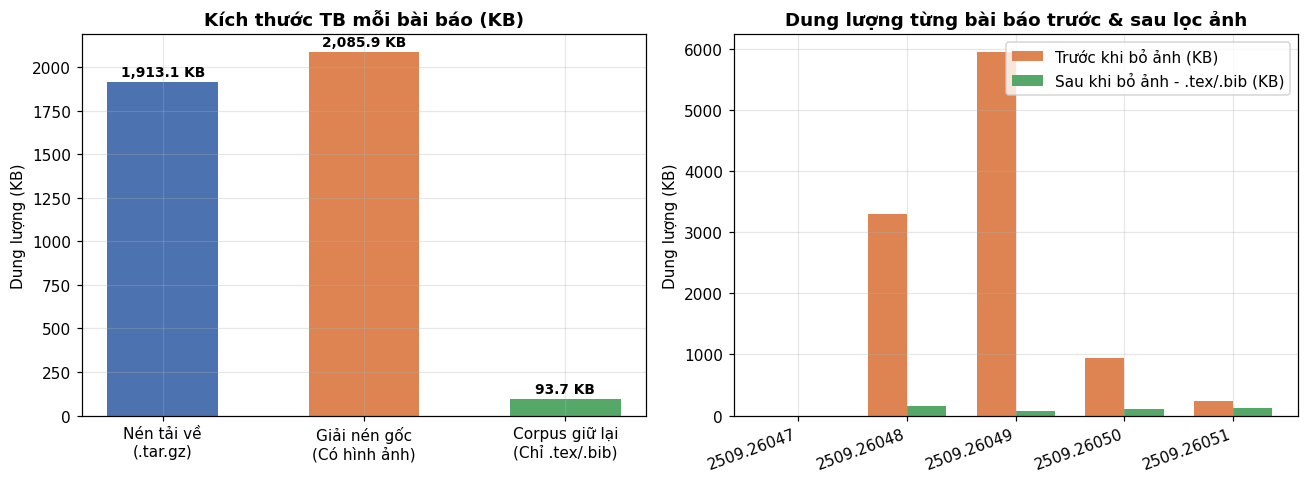

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Biểu đồ 1: So sánh kích thước trung bình 1 bài báo trước và sau khi lọc ảnh (KB)
labels_1 = ["Nén tải về\n(.tar.gz)", "Giải nén gốc\n(Có hình ảnh)", "Corpus giữ lại\n(Chỉ .tex/.bib)"]
vals_1 = [
    sizes["avg_compressed_bytes_per_paper"] / 1024,
    sizes["avg_uncompressed_bytes_per_paper_before_filtering"] / 1024,
    sizes["avg_retained_bytes_per_paper_after_filtering"] / 1024,
]
colors_1 = ["#4C72B0", "#DD8452", "#55A868"]
bars = axes[0].bar(labels_1, vals_1, color=colors_1, width=0.55)
axes[0].set_title("Kích thước TB mỗi bài báo (KB)", fontweight="bold")
axes[0].set_ylabel("Dung lượng (KB)")
for bar in bars:
    h = bar.get_height()
    axes[0].annotate(f"{h:,.1f} KB", xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, fontweight="bold")

# Biểu đồ 2: So sánh theo từng bài báo trong mẫu chạy
df_papers = pd.DataFrame(per_paper)
if not df_papers.empty:
    x = range(len(df_papers))
    w = 0.36
    axes[1].bar([i - w/2 for i in x], df_papers["archive_uncompressed_bytes"] / 1024,
                width=w, label="Trước khi bỏ ảnh (KB)", color="#DD8452")
    axes[1].bar([i + w/2 for i in x], df_papers["retained_tex_bib_bytes"] / 1024,
                width=w, label="Sau khi bỏ ảnh - .tex/.bib (KB)", color="#55A868")
    axes[1].set_xticks(list(x))
    axes[1].set_xticklabels(df_papers["arxiv_id"], rotation=20, ha="right")
    axes[1].set_title("Dung lượng từng bài báo trước & sau lọc ảnh", fontweight="bold")
    axes[1].set_ylabel("Dung lượng (KB)")
    axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Bảng chi tiết từng bài báo đã thu thập

In [5]:
if not df_papers.empty:
    display_cols = [
        "arxiv_id",
        "discovery_status",
        "versions_discovered",
        "versions_completed",
        "tex_files_count",
        "bib_files_count",
        "archive_uncompressed_bytes",
        "retained_tex_bib_bytes",
        "total_paper_seconds",
    ]
    df_show = df_papers[display_cols].rename(columns={
        "arxiv_id": "arXiv ID",
        "discovery_status": "Discovery",
        "versions_discovered": "Số version",
        "versions_completed": "Version hoàn tất",
        "tex_files_count": "Số file .tex",
        "bib_files_count": "Số file .bib",
        "archive_uncompressed_bytes": "Bytes gốc (có ảnh)",
        "retained_tex_bib_bytes": "Bytes giữ lại (.tex/.bib)",
        "total_paper_seconds": "Thời gian (s)",
    })
else:
    df_show = pd.DataFrame()
df_show

,arXiv ID,Discovery,Số version,Version hoàn tất,Số file .tex,Số file .bib,Bytes gốc (có ảnh),Bytes giữ lại (.tex/.bib),Thời gian (s)
0,2509.26047,resolved,1,0,0,0,0,0,17.5078
1,2509.26048,resolved,2,2,28,2,3374094,159762,0.0042
2,2509.26049,resolved,1,1,1,0,6087350,72260,0.0142
3,2509.26050,resolved,1,1,8,1,969721,116103,0.0015
4,2509.26051,resolved,1,1,1,1,248478,131430,0.0009


## 4. Hiệu năng Hệ thống: Thời gian chạy (Runtime), Bộ nhớ RAM và Ổ đĩa (Disk Footprint)

In [6]:
perf_rows = [
    {"Chỉ số Hiệu năng & Tài nguyên": "Môi trường kiểm thử (Testbed Platform)", "Giá trị đo được": f"{env['platform']} (Python {env['python_version']}, {env['cpu_count_logical']} vCPUs)"},
    {"Chỉ số Hiệu năng & Tài nguyên": "Thời gian chạy Discovery (Entry Discovery Time)", "Giá trị đo được": f"{perf['discovery_elapsed_seconds']:.2f} giây"},
    {"Chỉ số Hiệu năng & Tài nguyên": "Thời gian chạy Download (Source Download Time)", "Giá trị đo được": f"{perf['download_elapsed_seconds']:.2f} giây"},
    {"Chỉ số Hiệu năng & Tài nguyên": "Thời gian chạy Extraction (TeX/Bib Extraction Time)", "Giá trị đo được": f"{perf['extraction_elapsed_seconds']:.4f} giây"},
    {"Chỉ số Hiệu năng & Tài nguyên": "Tổng thời gian toàn tuyến (End-to-End Wall Time)", "Giá trị đo được": f"{perf['end_to_end_wall_time_seconds']:.2f} giây"},
    {"Chỉ số Hiệu năng & Tài nguyên": "Thời gian xử lý trung bình 1 bài báo (Avg Time / Paper)", "Giá trị đo được": f"{perf['avg_time_per_resolved_paper_seconds']:.2f} giây/bài"},
    {"Chỉ số Hiệu năng & Tài nguyên": "Thời gian xử lý 1 bài nhanh nhất / lâu nhất (Min / Max)", "Giá trị đo được": f"{perf['min_paper_processing_seconds']:.2f}s / {perf['max_paper_processing_seconds']:.2f}s"},
    {"Chỉ số Hiệu năng & Tài nguyên": "Bộ nhớ RAM tiêu thụ trung bình (Average RAM)", "Giá trị đo được": f"{res['avg_ram_mb']:.2f} MB ({res['samples_count']} mẫu, chu kỳ {res['sample_interval_seconds']}s)"},
    {"Chỉ số Hiệu năng & Tài nguyên": "Bộ nhớ RAM tiêu thụ cực đại (Peak RAM)", "Giá trị đo được": f"{res['peak_ram_mb']:.2f} MB"},
    {"Chỉ số Hiệu năng & Tài nguyên": "Dung lượng ổ đĩa làm việc cực đại (Peak Working Disk)", "Giá trị đo được": f"{res['peak_working_disk_mb']:.3f} MB"},
    {"Chỉ số Hiệu năng & Tài nguyên": "Dung lượng Corpus đầu ra cuối cùng (Final Corpus Size)", "Giá trị đo được": f"{res['final_corpus_disk_mb']:.3f} MB"},
]
pd.DataFrame(perf_rows)

,Chỉ số Hiệu năng & Tài nguyên,Giá trị đo được
0,Môi trường kiểm thử (Testbed Platform),"Windows-11-10.0.26200-SP0 (Python 3.13.5, 16 v..."
1,Thời gian chạy Discovery (Entry Discovery Time),0.00 giây
2,Thời gian chạy Download (Source Download Time),17.54 giây
3,Thời gian chạy Extraction (TeX/Bib Extraction ...,0.0079 giây
4,Tổng thời gian toàn tuyến (End-to-End Wall Time),17.68 giây
5,Thời gian xử lý trung bình 1 bài báo (Avg Time...,3.54 giây/bài
6,Thời gian xử lý 1 bài nhanh nhất / lâu nhất (M...,0.00s / 17.51s
7,Bộ nhớ RAM tiêu thụ trung bình (Average RAM),"99.73 MB (34 mẫu, chu kỳ 0.5s)"
8,Bộ nhớ RAM tiêu thụ cực đại (Peak RAM),99.73 MB
9,Dung lượng ổ đĩa làm việc cực đại (Peak Workin...,25.010 MB


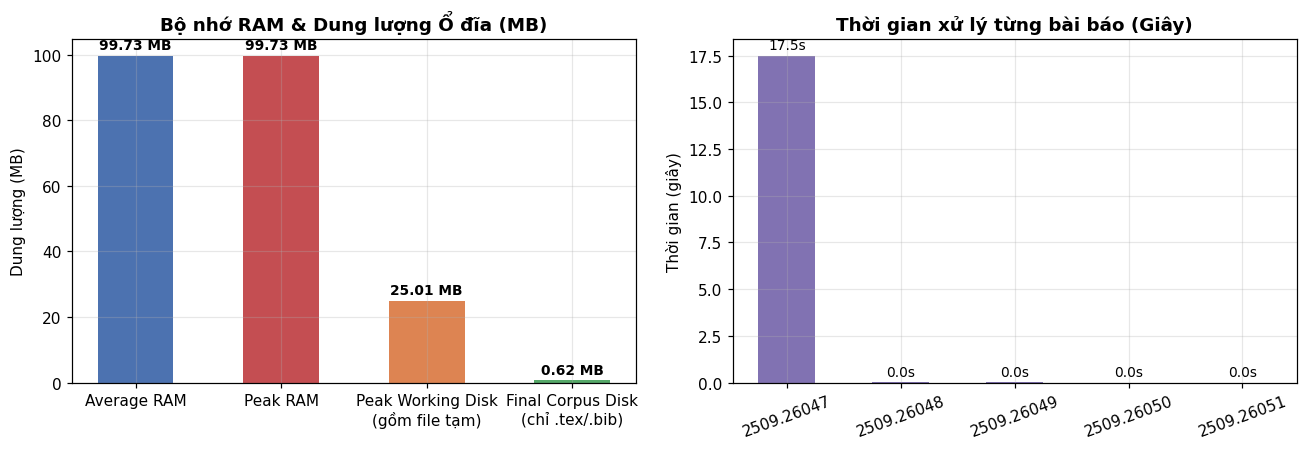

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Biểu đồ 1: RAM và Disk Footprint (MB)
res_labels = ["Average RAM", "Peak RAM", "Peak Working Disk\n(gồm file tạm)", "Final Corpus Disk\n(chỉ .tex/.bib)"]
res_vals = [
    res["avg_ram_mb"],
    res["peak_ram_mb"],
    res["peak_working_disk_mb"],
    res["final_corpus_disk_mb"],
]
res_colors = ["#4C72B0", "#C44E52", "#DD8452", "#55A868"]
b1 = axes[0].bar(res_labels, res_vals, color=res_colors, width=0.52)
axes[0].set_title("Bộ nhớ RAM & Dung lượng Ổ đĩa (MB)", fontweight="bold")
axes[0].set_ylabel("Dung lượng (MB)")
for bar in b1:
    h = bar.get_height()
    axes[0].annotate(f"{h:.2f} MB", xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, fontweight="bold")

# Biểu đồ 2: Thời gian xử lý từng bài báo (giây)
if not df_papers.empty:
    b2 = axes[1].bar(df_papers["arxiv_id"], df_papers["total_paper_seconds"], color="#8172B2", width=0.5)
    axes[1].set_title("Thời gian xử lý từng bài báo (Giây)", fontweight="bold")
    axes[1].set_ylabel("Thời gian (giây)")
    axes[1].tick_params(axis="x", rotation=20)
    for bar in b2:
        h = bar.get_height()
        axes[1].annotate(f"{h:.1f}s", xy=(bar.get_x() + bar.get_width() / 2, h),
                         xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)

plt.tight_layout()
plt.show()